# 4.3 Теплопроводность: явная схема FTCS

# 4.3 热传导：显式 FTCS 格式

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (7, 4.3), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.2})

Matplotlib is building the font cache; this may take a moment.


## Нагрев стержня
$$T_t=\alpha T_{xx},\qquad 0<x<L.$$
$L=0.10$ м, $\alpha=10^{-4}$ м²/с. Изначально внутри стержня $20\,°C$.
С момента $t=0$ левая граница поддерживается при $100\,°C$, правая при $20\,°C$. Резкое изменение температуры на левом конце соответствует включению нагрева.

## 杆的加热
杆长 0.10 m，热扩散率为 $10^{-4}$ m²/s，内部初温为 20 °C。自 t=0 起，左端维持 100 °C，右端维持 20 °C。左端初始温度突变表示突然开始加热。

In [2]:
alpha, L, Nx = 1e-4, 0.10, 51
TL, TR = 100.0, 20.0
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]
T_initial = np.full(Nx, 20.0)
T_initial[0], T_initial[-1] = TL, TR

## Временной шаг
$$\mathrm{Fo}=\frac{\alpha\Delta t}{\Delta x^2},\qquad\mathrm{Fo}\leq\frac12.$$
Это условие устойчивости одномерной FTCS-схемы на равномерной сетке при постоянной $\alpha$.

## 时间步长
对于均匀网格、常热扩散率的一维 FTCS 格式，稳定性条件为 $\mathrm{Fo}\leq1/2$。

In [3]:
Fo = 0.4
dt = Fo*dx**2/alpha
n_steps = 500
print(f"dx={dx:g} м / m; dt={dt:g} с / s")
print(f"Конечное время / 最终时刻: {n_steps*dt:g} с / s")

dx=0.002 м / m; dt=0.016 с / s
Конечное время / 最终时刻: 8 с / s


## Обновление внутренних узлов
Все значения справа относятся к старому слою. `T_new` хранит новый слой, а копии в `history` сохраняют предыдущие состояния. Ограничение Fo намеренно не встроено в функцию: ниже используем её и для демонстрации неустойчивости.

## 更新内部节点
右侧各项都来自旧时间层。`T_new` 保存新时间层，`history` 中保存独立副本。本函数不强制限制 Fo，因为后面还要演示违反稳定条件的情况。

In [4]:
def ftcs(T_initial, Fo, n_steps, TL, TR):
    T = np.asarray(T_initial, dtype=float).copy()
    T[0], T[-1] = TL, TR
    history = [T.copy()]
    for n in range(n_steps):
        T_new = T.copy()
        T_new[1:-1] = (T[1:-1] + Fo *
                      (T[2:] - 2*T[1:-1] + T[:-2]))
        T_new[0], T_new[-1] = TL, TR
        T = T_new
        history.append(T.copy())
    return np.array(history)

In [5]:
history = ftcs(T_initial, Fo, n_steps, TL, TR)
T_final = history[-1]
print(f"T(L/2, 8 с)={T_final[Nx//2]:.6f} °C")
print("Границы / 边界:", T_final[[0, -1]])
print("Диапазон / 温度范围:", T_final.min(), T_final.max())

T(L/2, 8 с)=36.905390 °C
Границы / 边界: [100.  20.]
Диапазон / 温度范围: 20.0 100.0


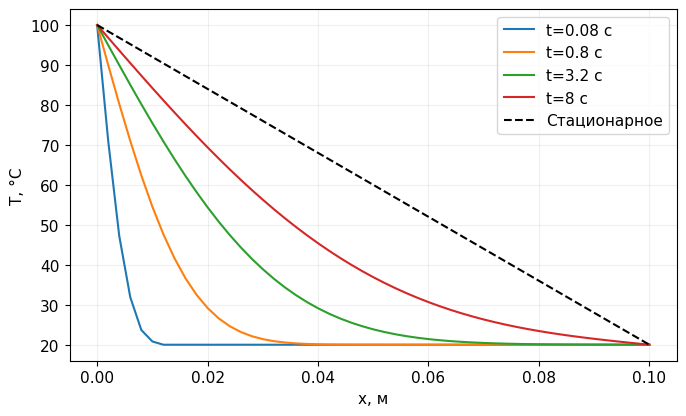

In [6]:
fig, ax = plt.subplots()
for step in [5, 50, 200, 500]:
    ax.plot(x, history[step], label=f"t={step*dt:g} с")
T_steady = TL + (TR-TL)*x/L
ax.plot(x, T_steady, "k--", label="Стационарное")
ax.set(xlabel="x, м", ylabel="T, °C")
ax.legend(); fig.tight_layout(); plt.show()

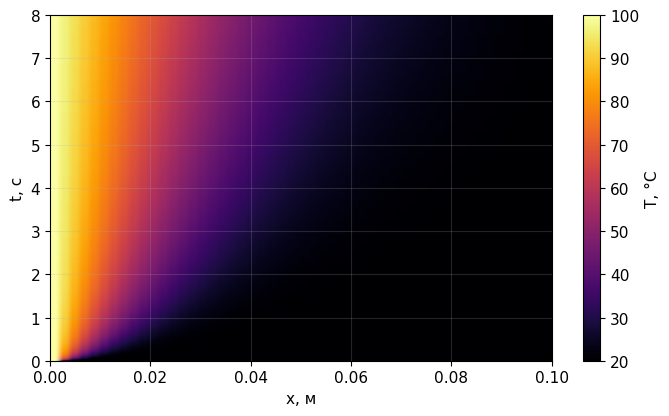

In [7]:
fig, ax = plt.subplots()
im = ax.imshow(history, origin="lower", aspect="auto",
               extent=[0, L, 0, n_steps*dt], vmin=20, vmax=100,
               cmap="inferno")
ax.set(xlabel="x, м", ylabel="t, с")
fig.colorbar(im, ax=ax, label="T, °C")
fig.tight_layout(); plt.show()

## Нарушение условия устойчивости
Сравним Fo=0.4 и Fo=0.6 до одного физического времени 1.92 с. Для разных Fo получаются разные шаги и разное число итераций.

## 违反稳定条件
将 Fo=0.4 与 Fo=0.6 都计算至相同物理时刻 1.92 s。不同 Fo 对应不同时间步长和迭代次数。

Fo=0.4: Tmin=2.000e+01, Tmax=1.000e+02
Fo=0.6: Tmin=-6.851e+10, Tmax=6.883e+10


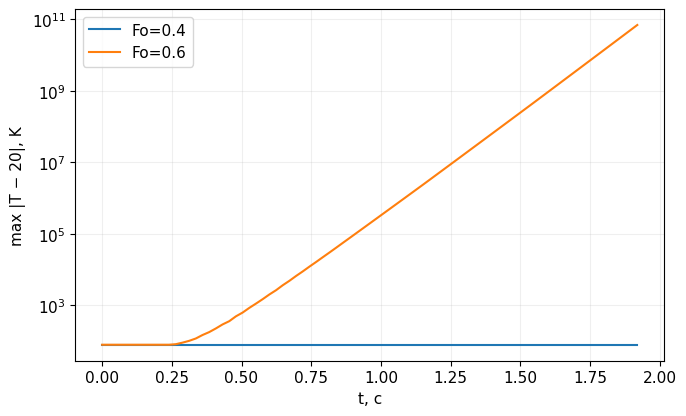

In [8]:
stability_runs = {}
for Fo_test in [0.4, 0.6]:
    dt_test = Fo_test*dx**2/alpha
    nt_test = round(1.92/dt_test)
    H = ftcs(T_initial, Fo_test, nt_test, TL, TR)
    times_test = np.arange(nt_test+1)*dt_test
    stability_runs[Fo_test] = (times_test, H)
    print(f"Fo={Fo_test}: Tmin={H[-1].min():.3e}, Tmax={H[-1].max():.3e}")
fig, ax = plt.subplots()
for Fo_test, (times_test, H) in stability_runs.items():
    amplitude = np.max(abs(H-TR), axis=1)
    ax.semilogy(times_test, amplitude, label=f"Fo={Fo_test}")
ax.set(xlabel="t, с", ylabel="max |T − 20|, K")
ax.legend(); fig.tight_layout(); plt.show()

## Проверка на известном решении
Для отдельного теста берём $T(0,t)=T(L,t)=20$ и $T(x,0)=20+80\sin(\pi x/L)$.
Точное решение: $T=20+80e^{-\alpha(\pi/L)^2t}\sin(\pi x/L)$.
При постоянном Fo шаг времени уменьшается пропорционально $\Delta x^2$. Для этого гладкого теста ожидаем общую ошибку порядка $\Delta x^2$.

## 使用已知解验证
另设测试问题：两端均为 20 °C，初温为正弦分布。解析解如上。固定 Fo 时，时间步长随空间步长的平方减小；此光滑测试的总误差应约为二阶。该测试的初始和边界条件与前面的单端加热不同。

In [9]:
grid_sizes = [26, 51, 101]
grid_dx, grid_errors = [], []
for nx in grid_sizes:
    xx = np.linspace(0, L, nx)
    ddx = xx[1]-xx[0]
    ddt = 0.4*ddx**2/alpha
    nt = round(8/ddt)
    initial = 20 + 80*np.sin(np.pi*xx/L)
    numeric = ftcs(initial, 0.4, nt, 20., 20.)[-1]
    exact = 20 + 80*np.exp(-alpha*(np.pi/L)**2*8)*np.sin(np.pi*xx/L)
    grid_dx.append(ddx)
    grid_errors.append(np.max(abs(numeric-exact)))
    print(f"Nx={nx:3d}, ошибка / 误差={grid_errors[-1]:.6e} K")
grid_errors = np.array(grid_errors)
print("Порядок / 阶数:", np.log2(grid_errors[:-1]/grid_errors[1:]))

Nx= 26, ошибка / 误差=5.285768e-02 K
Nx= 51, ошибка / 误差=1.321712e-02 K
Nx=101, ошибка / 误差=3.302821e-03 K
Порядок / 阶数: [1.9997048  2.00063759]
